### Exploratory Data Analysis

Importing Libraries

In [4]:
import numpy as np
import matplotlib.pyplot as plt 
import pandas as pd

Reading excel file and displaying the first 5 rows of the dataframe.

In [5]:
df = pd.read_excel("Telco_customer_churn.xlsx")
print(df.shape)
print(df.head())

(7043, 33)
   CustomerID  Count        Country       State         City  Zip Code  \
0  3668-QPYBK      1  United States  California  Los Angeles     90003   
1  9237-HQITU      1  United States  California  Los Angeles     90005   
2  9305-CDSKC      1  United States  California  Los Angeles     90006   
3  7892-POOKP      1  United States  California  Los Angeles     90010   
4  0280-XJGEX      1  United States  California  Los Angeles     90015   

                 Lat Long   Latitude   Longitude  Gender  ...        Contract  \
0  33.964131, -118.272783  33.964131 -118.272783    Male  ...  Month-to-month   
1   34.059281, -118.30742  34.059281 -118.307420  Female  ...  Month-to-month   
2  34.048013, -118.293953  34.048013 -118.293953  Female  ...  Month-to-month   
3  34.062125, -118.315709  34.062125 -118.315709  Female  ...  Month-to-month   
4  34.039224, -118.266293  34.039224 -118.266293    Male  ...  Month-to-month   

  Paperless Billing             Payment Method  Monthly C

isna().sum() gives the count of missing values in each column of the dataframe.

In [6]:
df.isna().sum()

CustomerID              0
Count                   0
Country                 0
State                   0
City                    0
Zip Code                0
Lat Long                0
Latitude                0
Longitude               0
Gender                  0
Senior Citizen          0
Partner                 0
Dependents              0
Tenure Months           0
Phone Service           0
Multiple Lines          0
Internet Service        0
Online Security         0
Online Backup           0
Device Protection       0
Tech Support            0
Streaming TV            0
Streaming Movies        0
Contract                0
Paperless Billing       0
Payment Method          0
Monthly Charges         0
Total Charges           0
Churn Label             0
Churn Value             0
Churn Score             0
CLTV                    0
Churn Reason         5174
dtype: int64

.nunique() gives the count of unique values in each column of the dataframe.

In [7]:
df.nunique()

CustomerID           7043
Count                   1
Country                 1
State                   1
City                 1129
Zip Code             1652
Lat Long             1652
Latitude             1652
Longitude            1651
Gender                  2
Senior Citizen          2
Partner                 2
Dependents              2
Tenure Months          73
Phone Service           2
Multiple Lines          3
Internet Service        3
Online Security         3
Online Backup           3
Device Protection       3
Tech Support            3
Streaming TV            3
Streaming Movies        3
Contract                3
Paperless Billing       2
Payment Method          4
Monthly Charges      1585
Total Charges        6531
Churn Label             2
Churn Value             2
Churn Score            85
CLTV                 3438
Churn Reason           20
dtype: int64

Dropping unnecessary columns.

In [8]:
cols_to_drop = list(df.columns[:9]) + [df.columns[-5]] + list(df.columns[-3:])
df =df.drop(columns=cols_to_drop)

df.columns

Index(['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months',
       'Phone Service', 'Multiple Lines', 'Internet Service',
       'Online Security', 'Online Backup', 'Device Protection', 'Tech Support',
       'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing',
       'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Value'],
      dtype='object')

pd.factorize & pd.get_dummies are used to convert categorical variables into numerical variables.  
  
However, pd.get_dummies is preferred when the categorical variable has more than 2 unique values. This is because pd.get_dummies creates a new column for each unique value in the categorical variable, while pd.factorize assigns a unique integer to each unique value.  
  
Using pd.factorize can lead to loss of information as it does assigns values (0, 1, 2, ...) to variables based on their order of appearance in the dataset, which may cause issue as test set may have different order. On the other hand, pd.get_dummies preserves the information about relationship between values and their categories.

In [9]:
# pd.facorize is not good as preprocessing step as it will assign numbers to the categories based on their order of appearance in the dataset. 
# This may go horribly wrong in test set as the order of appearance of the categories may be different in the test set.

# cols=list(df.columns[:4]) + list(df.columns[5:17]) + [df.columns[18]]
# print(cols)
# for col in cols:
#     df[col] = pd.factorize(df[col])[0]
# df.head()

In [10]:
print(df['Payment Method'].unique())
print(df['Payment Method'].nunique())

['Mailed check' 'Electronic check' 'Bank transfer (automatic)'
 'Credit card (automatic)']
4


Checking the distribution of categorical features.

In [11]:
for col in df.columns:
    if  df[col].nunique() < 5:
        print(f"Column: {col}")
        print(df[col].value_counts())


Column: Gender
Gender
Male      3555
Female    3488
Name: count, dtype: int64
Column: Senior Citizen
Senior Citizen
No     5901
Yes    1142
Name: count, dtype: int64
Column: Partner
Partner
No     3641
Yes    3402
Name: count, dtype: int64
Column: Dependents
Dependents
No     5416
Yes    1627
Name: count, dtype: int64
Column: Phone Service
Phone Service
Yes    6361
No      682
Name: count, dtype: int64
Column: Multiple Lines
Multiple Lines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64
Column: Internet Service
Internet Service
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64
Column: Online Security
Online Security
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64
Column: Online Backup
Online Backup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64
Column: Device Protection
Devic

Mapping the feature variables to 0, 1, 2, ...

In [12]:
df['Gender'] = df['Gender'].map({'Female':0, 'Male':1})
mapping = {'Yes':1, 'No':0}
df['Senior Citizen'] = df['Senior Citizen'].map(mapping)
df['Partner'] = df['Partner'].map(mapping)
df['Dependents'] = df['Dependents'].map(mapping)
df['Phone Service'] = df['Phone Service'].map(mapping)
df['Multiple Lines'] = df['Multiple Lines'].map({'Yes':1, 'No':0, 'No phone service':2})
df['Internet Service'] = df['Internet Service'].map({'DSL':1, 'Fiber optic':2, 'No':0})
df['Online Security'] = df['Online Security'].map({'Yes':1, 'No':0, 'No internet service':2})
df['Online Backup'] = df['Online Backup'].map({'Yes':1, 'No':0, 'No internet service':2})
df['Device Protection'] = df['Device Protection'].map({'Yes':1, 'No':0, 'No internet service':2})
df['Tech Support'] = df['Tech Support'].map({'Yes':1, 'No':0, 'No internet service':2})
df['Streaming TV'] = df['Streaming TV'].map({'Yes': 1, 'No':0, 'No internet service':2})
df['Streaming Movies'] = df['Streaming Movies'].map({'Yes':1, 'No':0, 'No internet service':2}) 
df['Contract'] = df['Contract'].map({'Month-to-month':0, 'One year':1, 'Two year':2})
df['Paperless Billing'] = df['Paperless Billing'].map(mapping)
df['Payment Method'] = df['Payment Method'].map({'Electronic check':0, 'Mailed check':1, 'Bank transfer (automatic)':2, 'Credit card (automatic)':3})

.hist() gives the histogram for each of the numerical column values.

array([[<Axes: title={'center': 'Gender'}>,
        <Axes: title={'center': 'Senior Citizen'}>,
        <Axes: title={'center': 'Partner'}>,
        <Axes: title={'center': 'Dependents'}>],
       [<Axes: title={'center': 'Tenure Months'}>,
        <Axes: title={'center': 'Phone Service'}>,
        <Axes: title={'center': 'Multiple Lines'}>,
        <Axes: title={'center': 'Internet Service'}>],
       [<Axes: title={'center': 'Online Security'}>,
        <Axes: title={'center': 'Online Backup'}>,
        <Axes: title={'center': 'Device Protection'}>,
        <Axes: title={'center': 'Tech Support'}>],
       [<Axes: title={'center': 'Streaming TV'}>,
        <Axes: title={'center': 'Streaming Movies'}>,
        <Axes: title={'center': 'Contract'}>,
        <Axes: title={'center': 'Paperless Billing'}>],
       [<Axes: title={'center': 'Payment Method'}>,
        <Axes: title={'center': 'Monthly Charges'}>,
        <Axes: title={'center': 'Churn Value'}>, <Axes: >]], dtype=object)

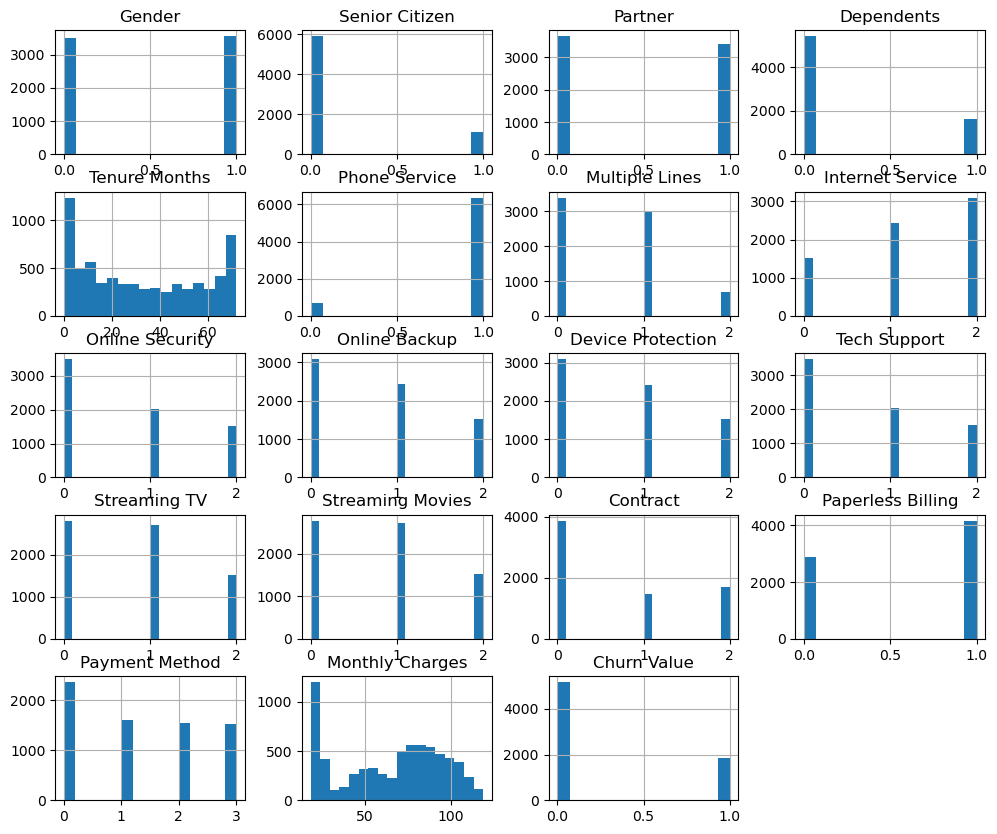

In [13]:
df.select_dtypes(include='number').hist(bins='auto', figsize=(12,10))

Using df.groupby(), we group unique categorical values to calculate both their frequency counts and their aggregated churn rates.

In [14]:
column = "Contract"

summary = (
    df.groupby(column, dropna=False)["Churn Value"]
      .agg(churn_rate="mean", total_customers="size")
      .sort_values("churn_rate", ascending=False)
)
summary

,churn_rate,total_customers
Contract,,
0,0.427097,3875
1,0.112695,1473
2,0.028319,1695


### Boxplot: Numerical Feature vs. Categorical Target

Boxplots are used to visualize the distribution of numerical features and identify potential outliers with respect to each category of the target variable.   
  
A boxplot compares the distribution of a numerical feature—such as `Tenure Months`, `Monthly Charges`, or `Total Charges`—across target groups (`Churn Value = 0` and `Churn Value = 1`).

- The **line inside each box** is the median.
- The **box** contains the middle 50% of observations (25 %ile to 75 %ile).
- The **whiskers** show the typical range beyond the box.
- Individual points beyond the whiskers are potential outliers.

Compare the boxes to see whether the feature tends to have different values for customers who stayed and customers who churned. For example, if the churn group has a lower median tenure, churned customers in the dataset tend to have shorter tenures. A boxplot shows an association; it does not prove that the feature causes churn.


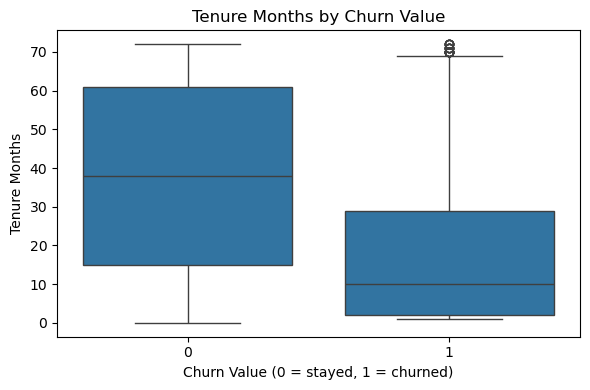

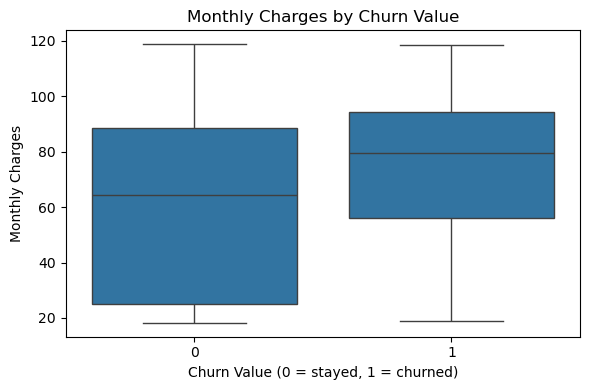

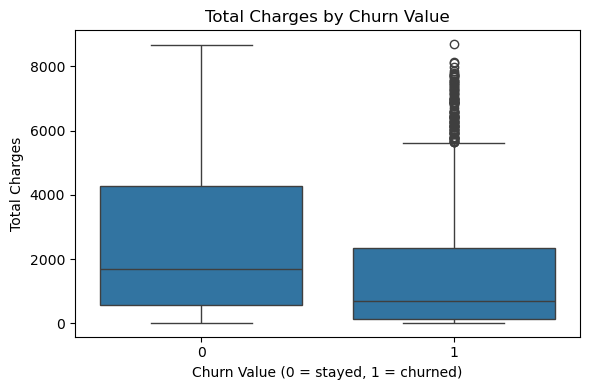

In [15]:
import seaborn as sns

feature_columns=df.columns[:-1]

numeric_columns = ["Tenure Months", "Monthly Charges", "Total Charges"]


df["Total Charges"] = pd.to_numeric(
    df["Total Charges"], errors="coerce"
)

# Numeric features: compare boxplot distributions for stayed vs churned.
for column in numeric_columns:
    plt.figure(figsize=(6, 4))
    sns.boxplot(data=df, x="Churn Value", y=column)
    plt.title(f"{column} by Churn Value")
    plt.xlabel("Churn Value (0 = stayed, 1 = churned)")
    plt.ylabel(column)
    plt.tight_layout()
    plt.show()



### Tenure Months by Churn Value

The boxplot compares customer tenure for customers who stayed (`Churn Value = 0`) and customers who churned (`Churn Value = 1`).

- The median tenure is higher for customers who stayed—about **38 months**—than for those who churned—about **10 months**.
- The middle 50% of churned customers had relatively short tenures compared with the middle 50% of customers who stayed.
- Some churned customers had long tenures; the points above the upper whisker are potential outliers.

In this dataset, **churn is associated with shorter tenure**. The plot describes an association; it does not show that short tenure causes churn.

### groupby analysis (Categorical features vs Categorical target variable):  
Using df.groupby(), we group unique categorical values of a feature column to calculate both their frequency counts and their corresponding aggregated churn rates.

In [16]:
categorical_columns = [
    col for col in feature_columns
    if col not in numeric_columns
]

# Categorical features: print churn rate and total customer count per unique category.
for column in categorical_columns:
    summary = (
        df.groupby(column, dropna=False)["Churn Value"]
        .agg(churn_rate="mean", total_customers="size")
        .sort_values("churn_rate", ascending=False)
    )

    summary["churn_rate"] = (summary["churn_rate"] * 100).round(1)

    print(f"\n{column}:")
    print(summary.to_string())


Gender:
        churn_rate  total_customers
Gender                             
0             26.9             3488
1             26.2             3555

Senior Citizen:
                churn_rate  total_customers
Senior Citizen                             
1                     41.7             1142
0                     23.6             5901

Partner:
         churn_rate  total_customers
Partner                             
0              33.0             3641
1              19.7             3402

Dependents:
            churn_rate  total_customers
Dependents                             
0                 32.6             5416
1                  6.5             1627

Phone Service:
               churn_rate  total_customers
Phone Service                             
1                    26.7             6361
0                    24.9              682

Multiple Lines:
                churn_rate  total_customers
Multiple Lines                             
1                     28.6    

### Heatmap


- **Heatmap** (Correlation between numerical features):  
A heatmap is used to visualize the correlation between numerical features in the dataset. The correlation coefficient ranges from -1 to 1, where -1 indicates a strong negative correlation, 0 indicates no correlation, and 1 indicates a strong positive correlation.  
  
- **Heatmap** is the most **best** correlation visualization technique as it provides a clear and intuitive representation of the relationships between numerical features, making them a powerful tool for exploratory data analysis.

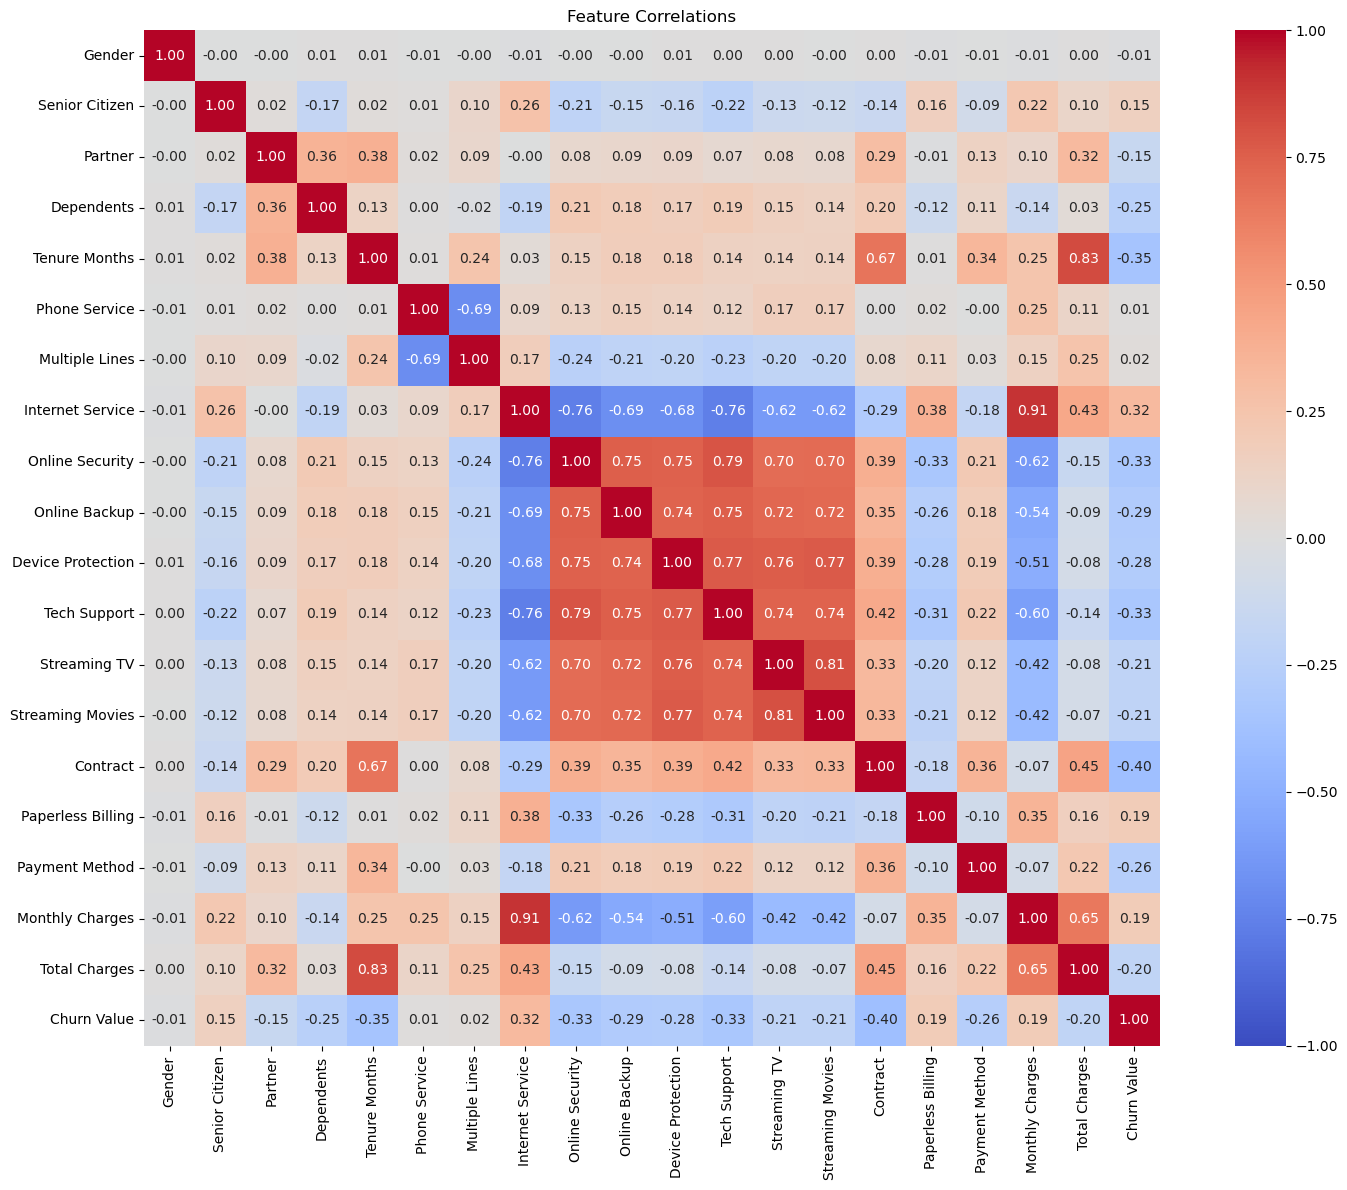

In [17]:
# Calculate correlations and plot the heatmap.
corr_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(16, 12))
sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    square=True,
)
plt.title("Feature Correlations")
plt.tight_layout()
plt.show()

## Correlation

Correlation describes the **direction and strength of a linear relationship** between two numerical variables. The Pearson correlation coefficient, usually written as `r`, ranges from **−1 to +1**. 

r = cov(Contract code, Churn Value)
    / [std(Contract code) × std(Churn Value)]
    
r = sum((xᵢ - x̄)(yᵢ - ȳ))
    / sqrt[sum((xᵢ - x̄)²) × sum((yᵢ - ȳ)²)]

Here, `xᵢ` and `yᵢ` are paired observations, while `x̄` and `ȳ` are the variables’ means. The formula compares how each observation differs from its variable’s mean. If both variables tend to be above or below their means together, correlation is positive. If one tends to be above its mean while the other is below, correlation is negative.


### Interpreting Example Values

| Correlation (`r`) | General interpretation |
|---:|---|
| `−0.90` | Very strong negative relationship |
| `−0.77` | Strong negative relationship |
| `−0.30` | Weak to moderate negative relationship |
| `0` | No linear relationship |
| `+0.35` | Weak to moderate positive relationship |
| `+0.75` | Strong positive relationship |
| `+0.95` | Very strong positive relationship |

- **Positive correlation:** As one variable increases, the other tends to increase.
- **Negative correlation:** As one variable increases, the other tends to decrease.
- **Correlation near zero:** There is little linear relationship. A nonlinear relationship may still exist.

These descriptions are guidelines, not strict cutoffs. Correlation does not prove that one variable causes a change in the other. Also, Pearson correlation should be interpreted carefully for categorical columns that have been assigned numeric codes.

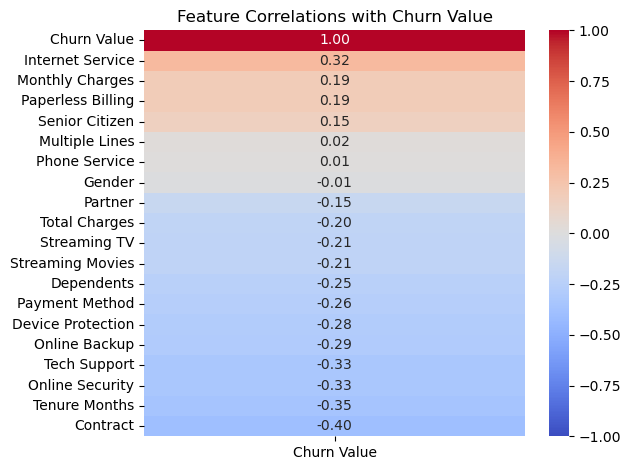

In [18]:

# Calculate correlations and plot the heatmap.
corr_matrix = df.corr(numeric_only=True)

# take the correlation of all features with the target variable "Churn Value" and sort them in descending order
churn_corr = corr_matrix["Churn Value"].sort_values( ascending=False)

sns.heatmap(
    churn_corr.to_frame(),
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
)
plt.title("Feature Correlations with Churn Value")
plt.tight_layout()
plt.show()

![Tenure and Churn Correlation Triptych.png](<attachment:Tenure and Churn Correlation Triptych.png>)
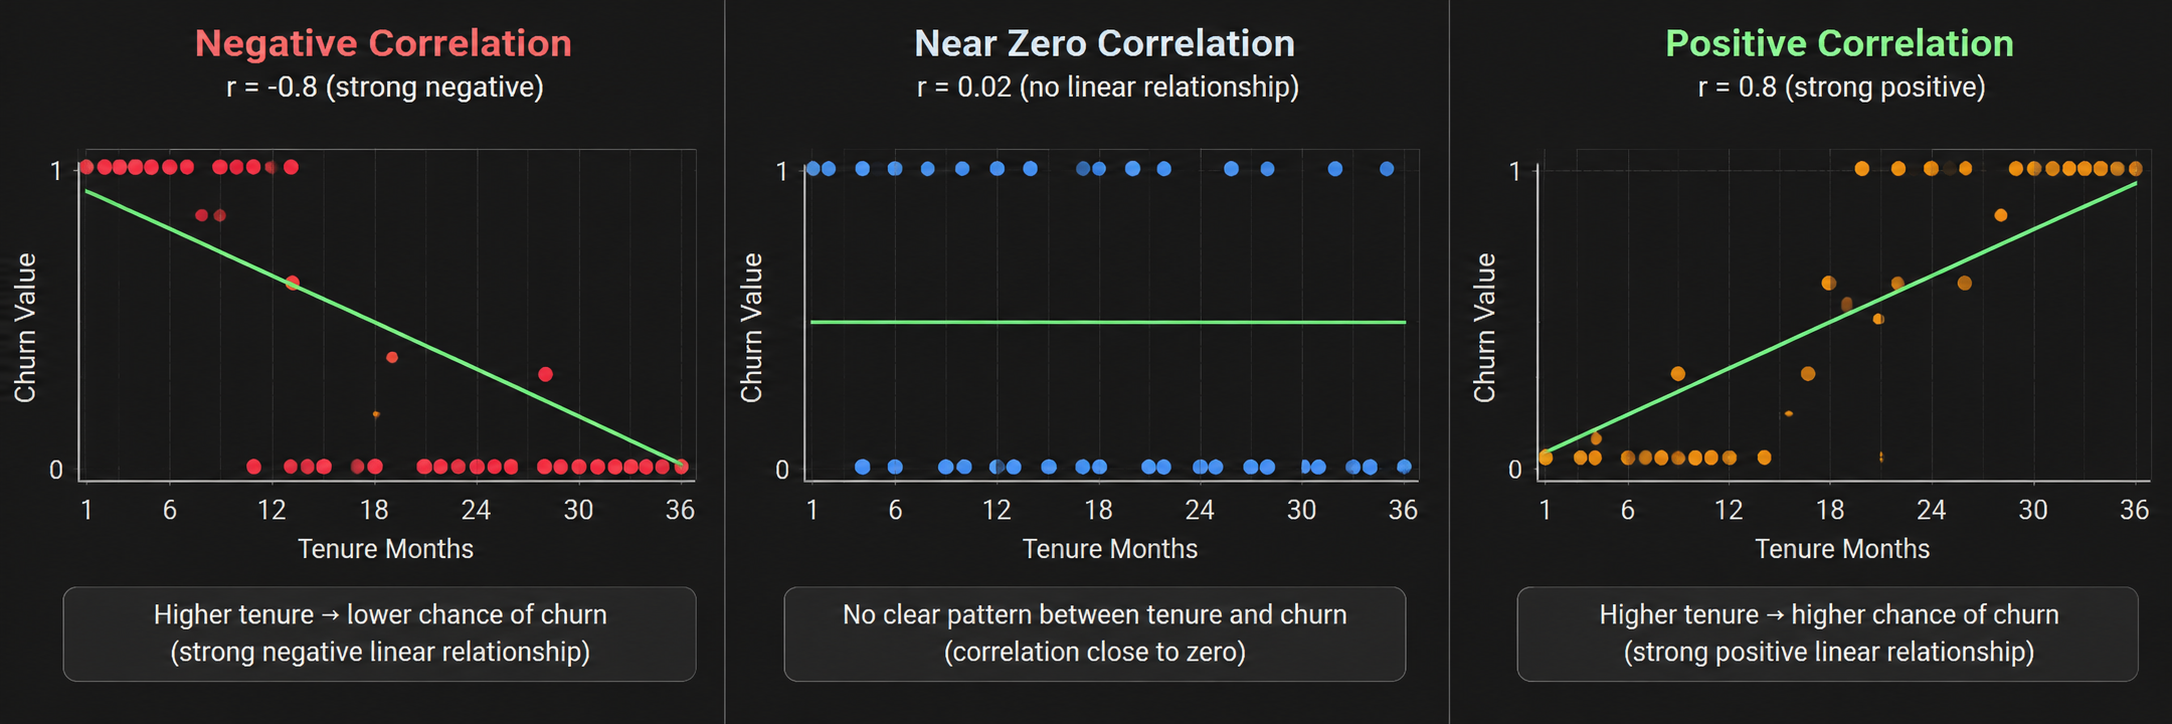

![Streaming TV and Churn Correlation Infographic.png](<attachment:Streaming TV and Churn Correlation Infographic.png>)
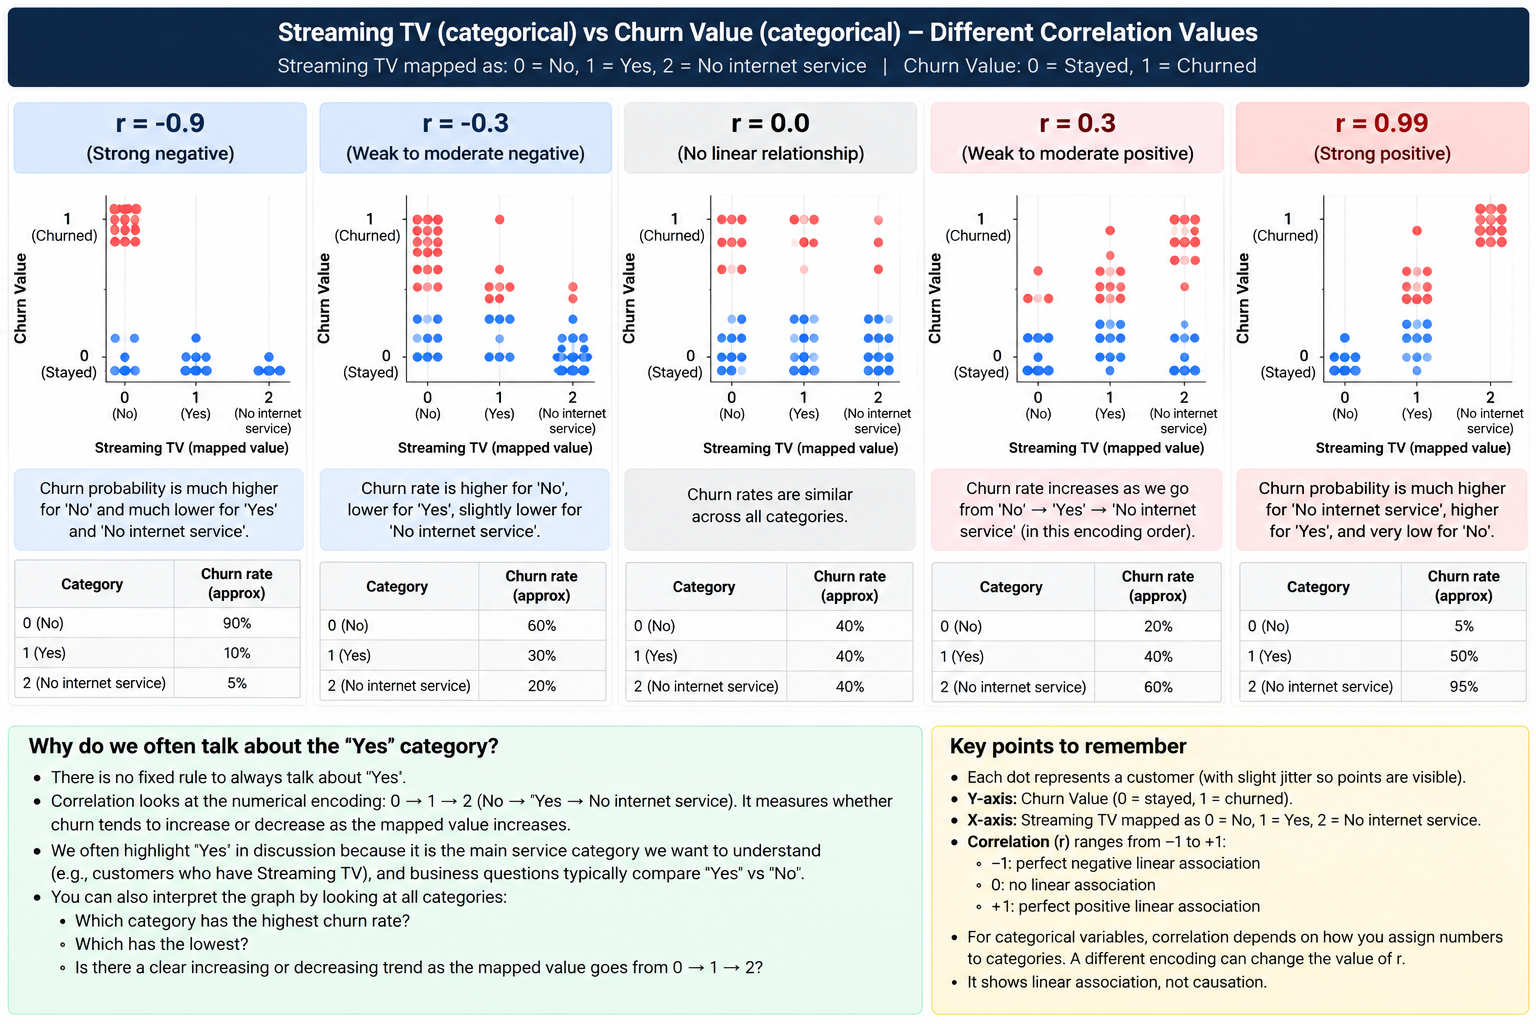

In [19]:


feature_corr = corr_matrix.drop(index="Churn Value", columns="Churn Value", errors="ignore")

# Keep only the upper half of the correlation matrix.
upper = feature_corr.where(
    np.triu(np.ones(feature_corr.shape), k=1).astype(bool)
)

# List feature pairs whose absolute correlation is at least 0.80.
threshold = 0.70

high_corr_pairs = (
    upper.stack()
    .rename("correlation")
    .reset_index()
    .rename(columns={"level_0": "feature_1", "level_1": "feature_2"})
)

high_corr_pairs = high_corr_pairs[
    high_corr_pairs["correlation"].abs() >= threshold
].sort_values("correlation", key=abs, ascending=False)

high_corr_pairs

,feature_1,feature_2,correlation
114,Internet Service,Monthly Charges,0.905491
79,Tenure Months,Total Charges,0.825880
150,Streaming TV,Streaming Movies,0.809608
118,Online Security,Tech Support,0.791225
135,Device Protection,Tech Support,0.767970
137,Device Protection,Streaming Movies,0.766821
105,Internet Service,Online Security,-0.764943
136,Device Protection,Streaming TV,0.763279
108,Internet Service,Tech Support,-0.760985
127,Online Backup,Tech Support,0.754095


### sklearn preprocessing pipeline

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer, StandardScaler

DROP_COLUMNS = [
    "CustomerID", "Count", "Country", "State", "City", "Zip Code",
    "Lat Long", "Latitude", "Longitude", "Churn Label", "Churn Score",
    "CLTV", "Churn Reason",
]

CATEGORY_MAPS = {
    "Gender": {"Female": 0, "Male": 1},
    "Senior Citizen": {"No": 0, "Yes": 1},
    "Partner": {"No": 0, "Yes": 1},
    "Dependents": {"No": 0, "Yes": 1},
    "Phone Service": {"No": 0, "Yes": 1},
    "Multiple Lines": {"No": 0, "Yes": 1, "No phone service": 2},
    "Internet Service": {"No": 0, "DSL": 1, "Fiber optic": 2},
    "Online Security": {"No": 0, "Yes": 1, "No internet service": 2},
    "Online Backup": {"No": 0, "Yes": 1, "No internet service": 2},
    "Device Protection": {"No": 0, "Yes": 1, "No internet service": 2},
    "Tech Support": {"No": 0, "Yes": 1, "No internet service": 2},
    "Streaming TV": {"No": 0, "Yes": 1, "No internet service": 2},
    "Streaming Movies": {"No": 0, "Yes": 1, "No internet service": 2},
    "Contract": {"Month-to-month": 0, "One year": 1, "Two year": 2},
    "Paperless Billing": {"No": 0, "Yes": 1},
    "Payment Method": {
        "Electronic check": 0,
        "Mailed check": 1,
        "Bank transfer (automatic)": 2,
        "Credit card (automatic)": 3,
    },
}


def preprocess_features(data):
    data = data.drop(columns=DROP_COLUMNS).copy()

    for column, mapping in CATEGORY_MAPS.items():
        data[column] = data[column].map(mapping).fillna(-1).astype(int)

    data["Total Charges"] = pd.to_numeric(data["Total Charges"], errors="coerce")
    return data

numeric_columns = ["Tenure Months", "Monthly Charges", "Total Charges"]


preprocessing_pipeline = Pipeline([
    ("preprocess", FunctionTransformer(preprocess_features)),
    ("scale", ColumnTransformer([
        ("numeric", Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ]), numeric_columns),
    ], remainder="passthrough")),
])

df = pd.read_excel("Telco_customer_churn.xlsx")

X = df.drop(columns=["Churn Value"])
y = df["Churn Value"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

X_train_processed = preprocessing_pipeline.fit_transform(X_train)
X_test_processed = preprocessing_pipeline.transform(X_test)

print("Train features:", X_train_processed.shape)
print("Test features:", X_test_processed.shape)
print("Train labels:", y_train.shape)
print("Test labels:", y_test.shape)



Train features: (5634, 19)
Test features: (1409, 19)
Train labels: (5634,)
Test labels: (1409,)


### sklearn model fit and prediction

In [21]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

models = {
    "Baseline": DummyClassifier(strategy="prior"),
    "Logistic Regression": LogisticRegression(
        max_iter=5000, class_weight="balanced", random_state=42
    ),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Support Vector Machine": SVC(
        probability=True, class_weight="balanced", random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced", random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "Gaussian Naive Bayes": GaussianNB(),
}

results = []

for name, model in models.items():
    model.fit(X_train_processed, y_train)
    predictions = model.predict(X_test_processed)
    probabilities = model.predict_proba(X_test_processed)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, predictions, labels=[0, 1]).ravel()

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "Specificity": tn / (tn + fp),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
    })

results_df = pd.DataFrame(results).set_index("Model").sort_values("F1", ascending=False)
results_df


c:\Users\raipu\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\raipu\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\raipu\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\raipu\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\raipu\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreatePro

,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,Specificity,TN,FP,FN,TP
Model,,,,,,,,,,,
Support Vector Machine,0.753726,0.767478,0.523726,0.796791,0.632025,0.837901,0.738164,764,271,76,298
Logistic Regression,0.740951,0.752806,0.507853,0.778075,0.614572,0.848327,0.727536,753,282,83,291
Gradient Boosting,0.804826,0.719441,0.663366,0.537433,0.593796,0.852403,0.901449,933,102,173,201
Gaussian Naive Bayes,0.717530,0.736010,0.480132,0.775401,0.593047,0.816647,0.696618,721,314,84,290
K-Nearest Neighbors,0.770050,0.710284,0.564767,0.582888,0.573684,0.796946,0.837681,867,168,156,218
Random Forest,0.790632,0.698680,0.632997,0.502674,0.560358,0.835685,0.894686,926,109,186,188
Decision Tree,0.745209,0.664347,0.521246,0.491979,0.506190,0.664822,0.836715,866,169,190,184
Baseline,0.734564,0.500000,0.000000,0.000000,0.000000,0.500000,1.000000,1035,0,374,0
